# Part 3: Question 2, Energy-Use Profiles of Chicago's Large Buildings

**Data science project: Decarbonizing Chicago's Large Buildings**

**Name:** Bernard Issifu

**Question 2.** What distinct energy-use profiles exist among Chicago's large buildings?

This notebook clusters buildings with k-means, using the cleaned data from Part 1 (run
`01_data_preparation_eda.ipynb` first). The R version is `r/03_q2_clustering.Rmd`.

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

bldg = pd.read_csv("../data/processed/buildings_latest_python.csv")
print(bldg.shape)

(3448, 23)


---
# 1. Approach

Question 1 showed that a building's characteristics say little about its emissions. Here the energy data
are used directly to ask how buildings *use* energy, without any predefined labels.

**Features (5).** For each building's latest report: *log site EUI* (how much energy per sq ft),
*log GHG intensity* (how much carbon per sq ft), and the *shares of energy from electricity, natural gas
and district steam/chilled water* (the energy mix). The logs tame the skew found in Part 1. All five are
standardized (z-scores) so that each counts equally in the distance calculation.

The ENERGY STAR score is **not** used to form the clusters, because it is missing for 14% of buildings
and does not exist for some property types; instead it is used afterwards, with property type, age and
size, to describe the clusters.

**Algorithm.** k-means (25 random starts per run, so the result does not depend on one unlucky start).
The number of clusters *k* is chosen by comparing the **elbow** in the within-cluster sum of squares
with the **average silhouette width** (how much closer each building is to its own cluster than to the
nearest other cluster; 1 is perfect, 0 means overlapping clusters), for *k* = 2 to 8.

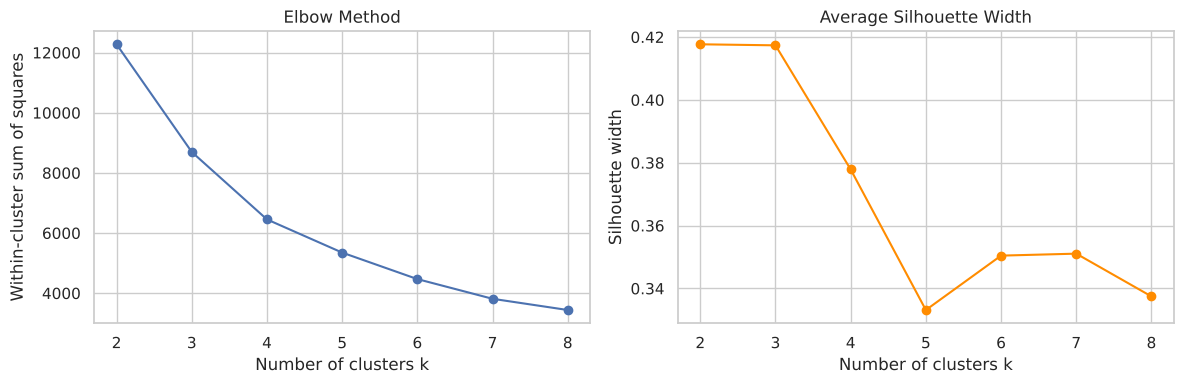

,within_ss,silhouette
k,,
2,12277.077,0.418
3,8695.438,0.417
4,6452.172,0.378
5,5348.908,0.333
6,4467.804,0.350
7,3812.561,0.351
8,3439.385,0.337


In [2]:
features = ["log_site_eui", "log_ghg_intensity", "elec_share", "gas_share", "district_share"]
X = StandardScaler().fit_transform(bldg[features])

ks = range(2, 9)
scores = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=25, random_state=42).fit(X)
    scores.append({"k": k, "within_ss": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
scores = pd.DataFrame(scores).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scores.index, scores["within_ss"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Within-cluster sum of squares")
axes[1].plot(scores.index, scores["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Average Silhouette Width")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette width")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_choose_k.png", dpi=150)
plt.show()
scores.round(3)

**Interpretation.** The silhouette width is highest for k = 2 (0.418) and k = 3 (0.417) and then falls to 0.378 at k = 4, while the elbow curve keeps dropping steeply up to k = 4 (within-cluster sum of squares 12,277 → 8,695 → 6,452) and flattens afterwards. **k = 4** is chosen: it is where the elbow bends, its silhouette is still reasonable, and, unlike k = 2 or 3, it separates the small group of district-energy buildings as its own profile, which matters for decarbonization because those buildings need a different solution.

---
# 2. The clusters

In [3]:
K = 4
km = KMeans(n_clusters=K, n_init=25, random_state=42).fit(X)
bldg["cluster"] = km.labels_

# Name each cluster from its average profile (so names do not depend on k-means' arbitrary numbering):
# highest district share -> district energy; then highest electricity share -> electric-led;
# then highest EUI -> energy-intensive; the remaining cluster -> gas-heated
prof = bldg.groupby("cluster")[["site_eui", "elec_share", "district_share"]].mean()
names, left = {}, list(prof.index)
for col, label in [("district_share", "District-energy buildings"),
                   ("elec_share", "Electric-led, low energy use"),
                   ("site_eui", "Energy-intensive, poor performers")]:
    c = prof.loc[left, col].idxmax()
    names[c] = label
    left.remove(c)
names[left[0]] = "Gas-heated, typical"
bldg["profile"] = bldg["cluster"].map(names)

profile = (bldg.groupby("profile")
           .agg(buildings=("ID", "size"),
                median_site_eui=("site_eui", "median"),
                median_ghg=("ghg_intensity", "median"),
                elec_share=("elec_share", "mean"),
                gas_share=("gas_share", "mean"),
                district_share=("district_share", "mean"),
                median_energy_star=("energy_star", "median"),
                median_age=("building_age", "median"),
                median_floor_area_k=("floor_area", lambda s: s.median() / 1000),
                total_ghg_kt=("ghg_total", lambda s: s.sum() / 1000))
           .sort_values("median_ghg"))
profile["share_of_total_ghg"] = profile["total_ghg_kt"] / profile["total_ghg_kt"].sum()
profile.round(2)

,buildings,median_site_eui,median_ghg,elec_share,gas_share,district_share,median_energy_star,median_age,median_floor_area_k,total_ghg_kt,share_of_total_ghg
profile,,,,,,,,,,,
"Gas-heated, typical",1946,68.70,5.4,0.28,0.71,0.00,70.0,60.0,111.27,2006.00,0.32
"Electric-led, low energy use",733,55.30,6.5,0.79,0.21,0.01,67.0,37.0,144.18,1690.69,0.27
"Energy-intensive, poor performers",680,120.75,10.4,0.42,0.58,0.00,26.0,45.0,111.78,2025.34,0.33
District-energy buildings,89,140.90,12.0,0.30,0.02,0.68,54.5,64.0,111.40,452.93,0.07


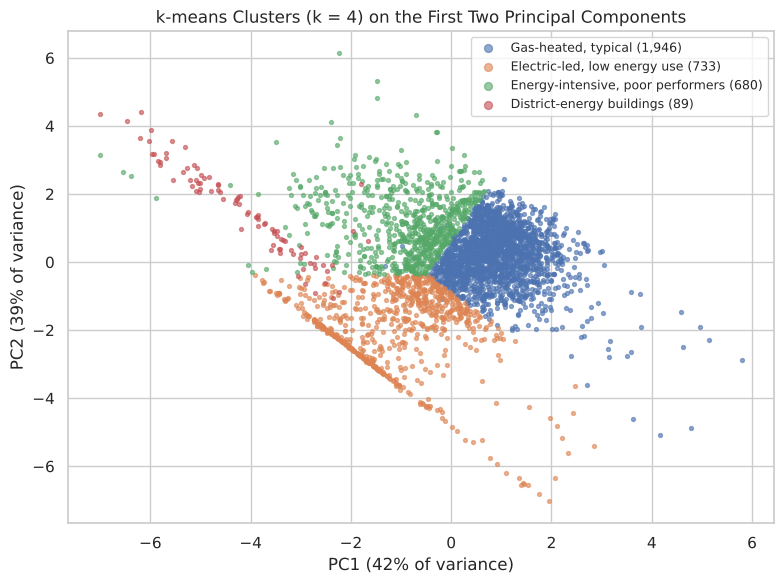

In [4]:
# Two-dimensional view of the clusters (first two principal components of the 5 features)
pca = PCA(n_components=2, random_state=42).fit(X)
pcs = pca.transform(X)
fig, ax = plt.subplots(figsize=(8, 6))
for name in profile.index:
    m = bldg["profile"] == name
    ax.scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.6, label=f"{name} ({m.sum():,})")
ax.set_title("k-means Clusters (k = 4) on the First Two Principal Components")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.legend(markerscale=2, loc="best", fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_clusters_pca.png", dpi=150)
plt.show()

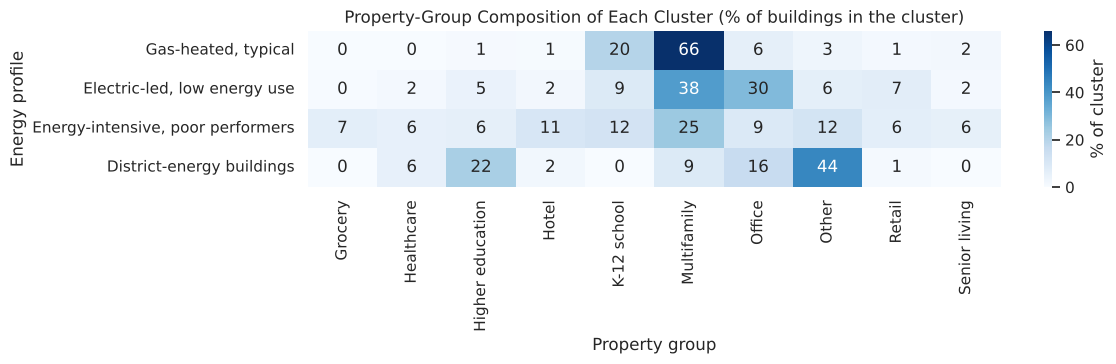

property_group,Grocery,Healthcare,Higher education,Hotel,K-12 school,Multifamily,Office,Other,Retail,Senior living
profile,,,,,,,,,,
"Gas-heated, typical",0.1,0.1,0.9,0.7,19.9,65.9,6.2,2.9,1.4,1.9
"Electric-led, low energy use",0.3,1.5,4.5,1.9,9.0,38.2,29.6,6.4,7.1,1.5
"Energy-intensive, poor performers",6.6,5.6,6.0,10.7,12.2,25.0,9.4,12.1,6.5,5.9
District-energy buildings,0.0,5.6,22.5,2.2,0.0,9.0,15.7,43.8,1.1,0.0


In [5]:
# Which property groups make up each cluster? (row percentages)
comp = pd.crosstab(bldg["profile"], bldg["property_group"], normalize="index").loc[profile.index]
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(comp * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of cluster"}, ax=ax)
ax.set_title("Property-Group Composition of Each Cluster (% of buildings in the cluster)")
ax.set_xlabel("Property group")
ax.set_ylabel("Energy profile")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_cluster_composition.png", dpi=150)
plt.show()
(comp * 100).round(1)

**Interpretation.** The four clusters are clearly different:

- **Gas-heated, typical** (1,946 buildings, 56%): 71% of energy from natural gas, moderate energy use (median 68.7 kBtu/sq ft), the lowest GHG intensity (5.4 kg/sq ft) and good ENERGY STAR scores (median 70). Two-thirds are multifamily buildings and a fifth are K-12 schools; they are the oldest group but one (median age 60).
- **Electric-led, low energy use** (733, 21%): 79% electricity, the lowest energy use (55.3 kBtu/sq ft), but a *higher* GHG intensity (6.5) than the gas-heated group, because each unit of grid electricity carries more CO2 than gas burned on site. This is where most offices sit (30% of the cluster) alongside newer multifamily buildings; median age 37.
- **Energy-intensive, poor performers** (680, 20%): nearly twice the energy use (120.8 kBtu/sq ft) and GHG intensity (10.4) of the typical building, with a median ENERGY STAR score of just **26**. Hotels, grocery stores, healthcare and "Other" buildings are over-represented, but a quarter are multifamily and 12% are schools: these are inefficient examples of ordinary building types.
- **District-energy buildings** (89, 3%): 68% of energy from district steam or chilled water, the highest energy use (140.9) and GHG intensity (12.0); dominated by "Other" uses (44%) and universities (23%).

The energy-intensive group is only 20% of buildings but produces **33% of the total emissions** (2.0 million tonnes CO2e), as much as the gas-heated group that has almost three times as many buildings.

In [6]:
profile.to_csv(f"{FIG_DIR}/q2_cluster_profiles_python.csv")
scores.to_csv(f"{FIG_DIR}/q2_choose_k_python.csv")

---
# 3. Discussion

Clustering turns the energy data into four archetypes, each with a different decarbonization
path:

1. **Energy-intensive, poor performers** are the priority. They emit a third of the total from a fifth
   of the buildings and score only 26 on ENERGY STAR, meaning they use more energy than three-quarters
   of similar buildings nationwide. Because many are ordinary multifamily buildings, schools and
   offices, their excess use is likely to come from fixable causes (old boilers, poor controls, leaky
   envelopes), so audits and retrofits should yield large savings.
2. **Gas-heated, typical** buildings are reasonably efficient, but their reliance on natural gas for
   heating means emissions will not fall much with a cleaner grid; they are the natural market for
   **electrification** (heat pumps, heat-pump water heaters).
3. **Electric-led** buildings already use little energy; their emissions will fall mostly as the
   electricity grid gets cleaner, and on-site solar or clean-power purchasing would help further.
4. **District-energy** buildings depend on central steam and chilled-water plants, so their emissions are
   decided mainly by how those plants are fuelled, not by individual building retrofits.

This complements Question 1: building type alone predicted only 28% of the variation in GHG intensity,
yet within every type some buildings fall into the energy-intensive profile. Finding them requires
measured energy data, which is exactly what benchmarking provides.

**Limitations.** k-means assumes roughly round, similar-sized clusters, and the silhouette values
(0.38 at k = 4) show the clusters overlap at their edges, especially between the gas-heated and
energy-intensive groups. The results depend on the chosen features and on self-reported data, and the
GHG figures depend on the emission factors the city uses for electricity and steam.